# NumCompute — Streaming Decision Tree Demo

This notebook trains a decision tree on a data stream, using only NumCompute (NumPy + matplotlib):

1. **Load** a CSV with missing values using `io.py`.
2. **Split** it into chunks to simulate streaming.
3. **Train incrementally** with `.partial_fit()`: imputer → scaler → `DecisionTreeClassifier` with buffered retraining, managed by `StreamTrainer`.
4. **Log and visualise** accuracy, error, memory and a model comparison with `visualise.py`.
5. **Benchmark** loop-based vs vectorised code, and different `buffer_size` values.

The dataset (`stream_data.csv`, made by `make_stream_data.py`) has 6,000 rows, four sensor features with 3% missing values, a binary label, and a **concept drift halfway through**: the rule that decides the label changes, so a model trained on old data becomes stale.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Run from a clone without installing the package.
sys.path.insert(0, str(Path.cwd().parent))

from numcompute import (
    DecisionTreeClassifier, Pipeline, SimpleImputer, StandardScaler,
    StreamTrainer, read_csv, read_csv_chunks,
    compare_models, plot_metric_over_time,
    plot_predictions_vs_ground_truth, plot_stream_log,
)
from numcompute.benchmarking import (
    benchmark_buffer_sizes, benchmark_running_stats, benchmark_tree_predict,
    benchmark_tree_streaming, environment_info,
)

%matplotlib inline
DATA = "stream_data.csv"
environment_info()

{'platform': 'Windows-10-10.0.26200-SP0',
 'processor': 'Intel64 Family 6 Model 165 Stepping 2, GenuineIntel',
 'python': '3.9.6',
 'numpy': '1.26.0'}

## 1. Load the CSV with `io.py`

`read_csv` uses `numpy.genfromtxt`; empty fields become NaN (`missing="fill"`). The header row is skipped.

In [2]:
data = read_csv(DATA, skip_header=1)
X_all, y_all = data[:, :4], data[:, 4].astype(int)

print("shape:", data.shape)
print("missing values per feature:", np.isnan(X_all).sum(axis=0))
print("class counts:", np.bincount(y_all))

shape: (6000, 5)
missing values per feature: [201 184 179 154]
class counts: [2835 3165]


## 2. Simulate a stream

`read_csv_chunks` reads the file **lazily**: only one chunk of 200 rows is in memory at a time. Each chunk is split into features and label.

In [3]:
CHUNK_SIZE = 200

def stream(path=DATA, chunk_size=CHUNK_SIZE):
    for chunk in read_csv_chunks(path, chunk_size=chunk_size, skip_header=1):
        yield chunk[:, :4], chunk[:, 4].astype(int)

chunks = list(stream())
print(f"{len(chunks)} chunks of {CHUNK_SIZE} rows")
print("missing values in the first chunk:", int(np.isnan(chunks[0][0]).sum()))

30 chunks of 200 rows
missing values in the first chunk: 26


## 3. Train incrementally with `partial_fit`

The pipeline imputes missing values (running median), standardises (running mean/variance with Welford's algorithm) and feeds a `DecisionTreeClassifier(max_depth=6, buffer_size=600)`. Each `partial_fit` adds the chunk to the tree's buffer; once 600 samples are buffered, the tree is **retrained on the buffer** and the buffer is cleared. Between retrains, `predict` uses the latest tree.

`StreamTrainer.process_chunk` evaluates **test-then-train**: each chunk is first scored by the model trained on *earlier* chunks, then passed to `pipe.partial_fit`. Every chunk is therefore unseen test data. The predictions for the last chunk are kept for section 6.

In [4]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("impute", SimpleImputer("median")),
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=6, buffer_size=buffer_size,
                                        random_state=0)),
    ])

pipe = make_pipeline(buffer_size=600)
trainer = StreamTrainer(pipe, metrics=("accuracy", "f1", "auc"), window=5)

for i, (X_chunk, y_chunk) in enumerate(chunks):
    if i == len(chunks) - 1:
        last_pred = pipe.predict(X_chunk)         # before training on it
    trainer.process_chunk(X_chunk, y_chunk)       # score, then pipe.partial_fit

print(f"{'chunk':>5} {'scored':>7} {'acc':>6} {'cum acc':>8} {'retrained':>10} "
      f"{'buffered':>9} {'memory KB':>10}")
for e in trainer.history_[:8] + trainer.history_[-3:]:
    print(f"{e['chunk']:>5} {str(e['scored']):>7} {e['chunk_accuracy']:>6.3f} "
          f"{e['cumulative_accuracy']:>8.3f} {str(e['retrained']):>10} "
          f"{e['n_buffered']:>9} {e['memory_bytes'] / 1024:>10.1f}")

chunk  scored    acc  cum acc  retrained  buffered  memory KB
    0   False    nan      nan      False       200       19.7
    1   False    nan      nan      False       400       39.0
    2   False    nan      nan       True         0       40.5
    3    True  0.905    0.905      False       200       59.9
    4    True  0.845    0.875      False       400       79.2
    5    True  0.890    0.880       True         0       35.7
    6    True  0.855    0.874      False       200       55.1
    7    True  0.915    0.882      False       400       74.3
   27    True  0.855    0.848      False       200       56.1
   28    True  0.850    0.848      False       400       75.1
   29    True  0.920    0.850       True         0       37.0


In [5]:
trainer.summary()

{'n_chunks': 30,
 'n_samples': 6000,
 'cumulative_accuracy': 0.8503703703703703,
 'cumulative_f1': 0.8572942423172024,
 'cumulative_auc': 0.8651948983370347,
 'total_fit_time': 0.17700840000000184,
 'n_retrains': 10,
 'final_memory_bytes': 37864}

The first chunks show `NaN`: no tree exists until 600 samples are buffered, so they cannot be scored. Memory grows while the buffer fills and drops after each retrain. The roughly 36 KB that remains is the imputer's bounded median summary plus the trained tree.

## 4. Metrics over time (`visualise.py`)

Per-chunk, rolling (last 5 chunks) and cumulative accuracy. The dashed line marks the concept drift.

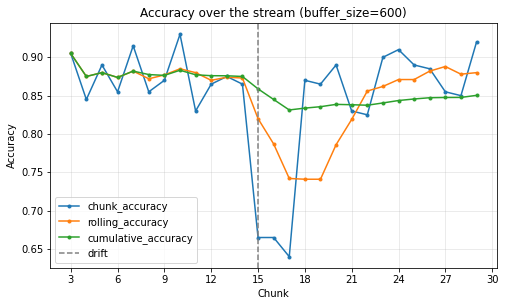

In [6]:
drift_chunk = len(chunks) // 2

fig = plot_stream_log(
    trainer,
    keys=("chunk_accuracy", "rolling_accuracy", "cumulative_accuracy"),
    title="Accuracy over the stream (buffer_size=600)", ylabel="Accuracy",
)
fig.axes[0].axvline(drift_chunk, color="grey", linestyle="--", label="drift")
fig.axes[0].legend()
plt.show()

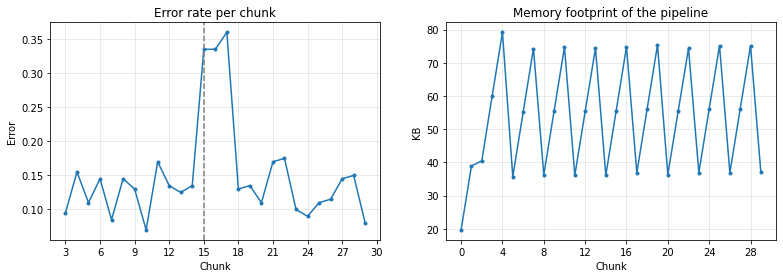

In [7]:
fig, (ax_err, ax_mem) = plt.subplots(1, 2, figsize=(13, 4))
plot_metric_over_time(1 - trainer.get_metric("chunk_accuracy"),
                      title="Error rate per chunk", ylabel="Error", ax=ax_err)
plot_metric_over_time(trainer.get_metric("memory_bytes") / 1024,
                      title="Memory footprint of the pipeline",
                      ylabel="KB", ax=ax_mem)
ax_err.axvline(drift_chunk, color="grey", linestyle="--")
plt.show()

## 5. Compare models: small vs large buffer

The same stream is processed by two pipelines that differ only in `buffer_size`.

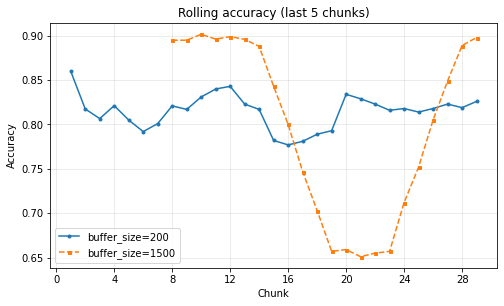

  buffer_size=200: accuracy 0.815, 30 retrains, peak memory 64.3 KB
 buffer_size=1500: accuracy 0.798, 3 retrains, peak memory 111.5 KB


In [8]:
small = StreamTrainer(make_pipeline(buffer_size=200), window=5).run(stream())
large = StreamTrainer(make_pipeline(buffer_size=1500), window=5).run(stream())

compare_models(small.get_metric("rolling_accuracy"),
               large.get_metric("rolling_accuracy"),
               labels=("buffer_size=200", "buffer_size=1500"),
               title="Rolling accuracy (last 5 chunks)", ylabel="Accuracy")
plt.show()

for name, t in (("buffer_size=200", small), ("buffer_size=1500", large)):
    s = t.summary()
    print(f"{name:>17}: accuracy {s['cumulative_accuracy']:.3f}, "
          f"{s['n_retrains']} retrains, peak memory "
          f"{t.get_metric('memory_bytes').max() / 1024:.1f} KB")

## 6. Predictions vs ground truth on the latest chunk

These predictions were made **before** the model trained on this chunk.

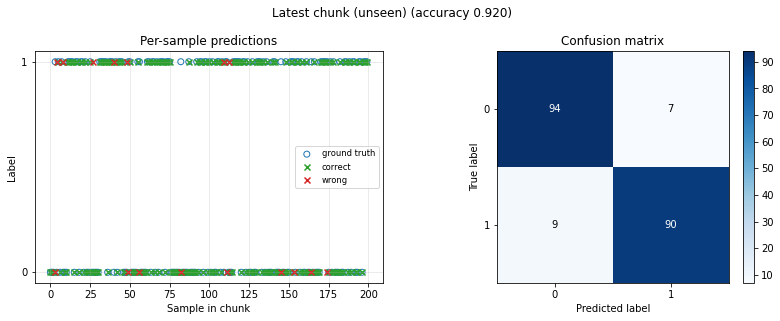

In [9]:
X_last, y_last = chunks[-1]
plot_predictions_vs_ground_truth(y_last, last_pred,
                                 title="Latest chunk (unseen)")
plt.show()

## 7. Benchmarks

### (a) Loop-based vs vectorised

Each pair is checked for identical results before timing. The loop-based tree is the same tree with its split search written as Python loops; streaming the same chunks into both gives identical trees.

In [10]:
rows = [benchmark_tree_streaming(repeats=3), benchmark_tree_predict(repeats=3),
        benchmark_running_stats(repeats=3)]

print(f"{'operation':<18}{'elements':>10}{'loop ms':>11}{'NumPy ms':>11}{'speedup':>9}")
for r in rows:
    print(f"{r['operation']:<18}{r['size']:>10,}{r['loop_time'] * 1e3:>11.1f}"
          f"{r['vector_time'] * 1e3:>11.1f}{r['speedup']:>8.1f}x")

operation           elements    loop ms   NumPy ms  speedup
Tree partial_fit       4,000      252.1       80.0     3.2x
Tree predict          20,000       32.0        5.7     5.6x
RunningStats         100,000       43.9        8.9     4.9x


### (b) Effect of `buffer_size` on this dataset

 buffer  accuracy  after drift  retrains  retrain ms  ms/retrain  peak KB
    100     0.804        0.804        60       310.3        5.17     64.9
    200     0.815        0.813        30       204.7        6.82     65.8
    400     0.839        0.825        15       167.1       11.14     73.8
    800     0.844        0.814         7       114.3       16.32     88.6
   1600     0.800        0.756         3        69.5       23.16    117.4


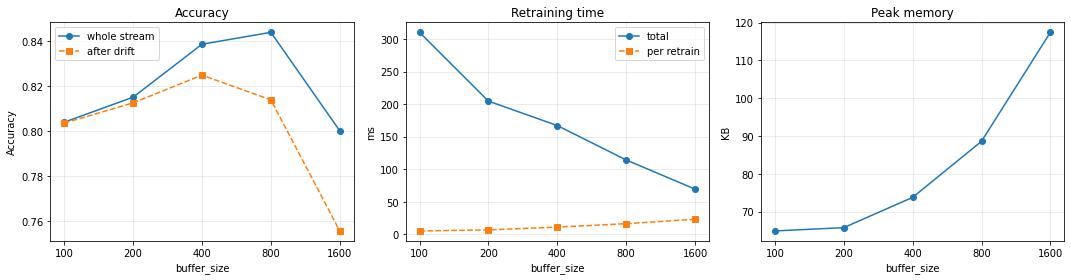

In [11]:
buffer_sizes = (100, 200, 400, 800, 1600)
results = benchmark_buffer_sizes(buffer_sizes, X=X_all, y=y_all, chunk_size=100)

print(f"{'buffer':>7}{'accuracy':>10}{'after drift':>13}{'retrains':>10}"
      f"{'retrain ms':>12}{'ms/retrain':>12}{'peak KB':>9}")
for r in results:
    print(f"{r['buffer_size']:>7}{r['accuracy']:>10.3f}{r['accuracy_after_drift']:>13.3f}"
          f"{r['n_retrains']:>10}{r['total_retrain_time'] * 1e3:>12.1f}"
          f"{r['mean_retrain_time'] * 1e3:>12.2f}{r['peak_memory_bytes'] / 1024:>9.1f}")

sizes = [r["buffer_size"] for r in results]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(sizes, [r["accuracy"] for r in results], "o-", label="whole stream")
axes[0].plot(sizes, [r["accuracy_after_drift"] for r in results], "s--",
             label="after drift")
axes[0].set(title="Accuracy", ylabel="Accuracy")
axes[0].legend()
axes[1].plot(sizes, [r["total_retrain_time"] * 1e3 for r in results], "o-",
             label="total")
axes[1].plot(sizes, [r["mean_retrain_time"] * 1e3 for r in results], "s--",
             label="per retrain")
axes[1].set(title="Retraining time", ylabel="ms")
axes[1].legend()
axes[2].plot(sizes, [r["peak_memory_bytes"] / 1024 for r in results], "o-")
axes[2].set(title="Peak memory", ylabel="KB")
for ax in axes:
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks(sizes)
    ax.set_xticklabels(sizes)
    ax.set_xlabel("buffer_size")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary

- `io.read_csv_chunks` streams the CSV lazily, and `SimpleImputer` handles its missing values on the fly.
- The tree is retrained each time the buffer fills. `predict` uses the latest tree, and memory rises and falls with the buffer.
- **`buffer_size` is a trade-off:**
  - *small buffers* retrain often on little data, which costs total time and accuracy;
  - *large buffers* retrain rarely but slowly, use more memory, and react late to the concept drift;
  - mid-sized buffers did best on this stream.
- The vectorised implementations give the same results as the loop-based ones and are faster.